# UCI Energy Efficiency Prediction (Heating Load)

## 1. Project Context & Problem Description
Assessing the energy efficiency of buildings during the early architectural design phase is crucial for constructing sustainable and cost-effective structures. Heating load ($Y_1$) represents the amount of heat energy needed to maintain a comfortable indoor temperature. 

By modeling heating load based on building geometry and physical attributes, architects and engineers can estimate energy requirements before construction begins.

## 2. Dataset Information
* **Source:** UCI Machine Learning Repository — [Energy Efficiency Dataset](https://archive.ics.uci.edu/dataset/242/energy+efficiency)
* **Target Variable:** `Y1` — Heating Load ($\text{kWh/m}^2$)
* **Problem Type:** Regression

In [3]:
# Import standard data science and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styles for plots later
%matplotlib inline
sns.set_theme(style="whitegrid")

# Load the Excel dataset from the local Data folder
df = pd.read_excel('Data/ENB2012_data.xlsx')

print("Dataset loaded successfully!")
print(f"Dataframe shape: {df.shape}")
df.head()

Dataset loaded successfully!
Dataframe shape: (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


### Features Overview

The descriptions and feature names below are sourced directly from the official UCI Energy Efficiency dataset documentation:

- `X1` — Relative Compactness
- `X2` — Surface Area ($\text{m}^2$)
- `X3` — Wall Area ($\text{m}^2$)
- `X4` — Roof Area ($\text{m}^2$)
- `X5` — Overall Height ($\text{m}$)
- `X6` — Orientation (2: North, 3: East, 4: South, 5: West)
- `X7` — Glazing Area (Percentage of window area)
- `X8` — Glazing Area Distribution (Location of windows)

In [4]:
# Print column names and their data types
print("--- Column Data Types ---")
print(df.dtypes)

# Check for missing values using isna()
print("\n--- Missing Values (isna) ---")
print(df.isna().sum())

--- Column Data Types ---
X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object

--- Missing Values (isna) ---
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64


> **Data Quality & Missing Value Inspection:** 
> An inspection of the dataset using `df.isna().sum()` confirms that there are **0 missing values** across all features ($X_1$–$X_8$) and target variables ($Y_1$, $Y_2$). 
> 
> * **Handling Strategy:** Because the dataset is fully complete, no data imputation or row dropping is required. In scenarios where missing data *is* present, standard mitigation strategies include:
>   * **Numerical Imputation:** Filling missing entries with statistical measures such as the median or mean (e.g., using `SimpleImputer(strategy='median')` from `scikit-learn` or `df.fillna()`).
>   * **Domain-Specific Imputation:** Leveraging categorical grouping (e.g., grouping by building type or orientation) to impute missing values more accurately.
>   * **Deletion:** Dropping rows or columns only if the missingness percentage is exceptionally high and dropping them won't introduce severe sampling bias.

> **Feature & Target Separation:** 
> We isolate our input features ($X_1$ through $X_8$) into matrix `X` and isolate our target variable to `Y1` (Heating Load) in array `y`, explicitly dropping `Y2` (Cooling Load) to prevent target leakage.

In [5]:
# Separate features (X1 to X8) and targets (Y1, Y2)
X = df.drop(columns=['Y1', 'Y2'])
y = df['Y1']  # Focusing strictly on Heating Load (Y1)

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

# Quick peek at the feature columns
X.head(3)

Features shape (X): (768, 8)
Target shape (y): (768,)


,X1,X2,X3,X4,X5,X6,X7,X8
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0


### Exploratory Data Analysis: Target Variable Distribution

Before training our models, it is essential to analyze the distribution of our target variable, **Heating Load (`Y1`)**. Understanding this distribution helps us identify:
* **Spread and Range:** The minimum and maximum energy requirements across the dataset.
* **Skewness or Multimodality:** Whether the target values are normally distributed or clustered around specific groups (which is common in architectural benchmark data due to different building designs).

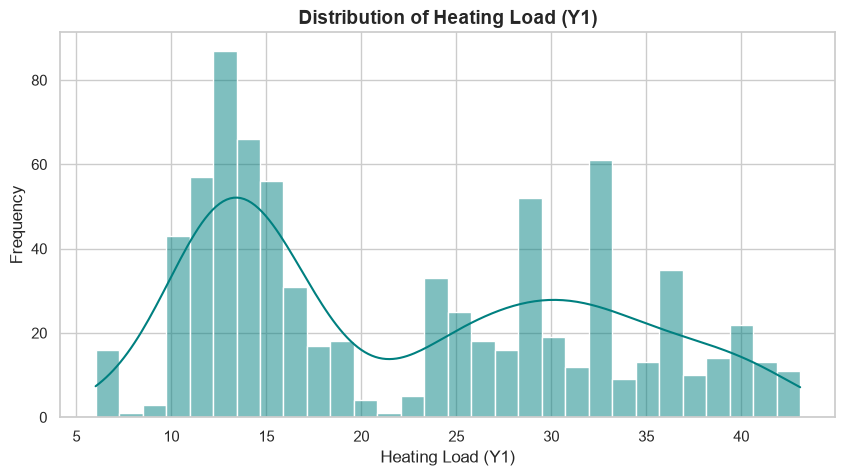

In [6]:
# Plot the distribution of Heating Load (Y1)
plt.figure(figsize=(10, 5))
sns.histplot(y, kde=True, color='teal', bins=30)
plt.title('Distribution of Heating Load (Y1)', fontsize=14, fontweight='bold')
plt.xlabel('Heating Load (Y1)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

### Feature Analysis: Correlation & Mutual Information (MI)

To understand how our features relate to the Heating Load (`Y1`), we will evaluate two complementary metrics:
1. **Pearson Correlation Matrix:** Measures the **linear** relationship between each feature and the target. This helps identify which architectural parameters strongly increase or decrease heating requirements linearly, while also checking for multicollinearity among features.
2. **Mutual Information (MI) Regression:** Measures **non-linear** dependencies. Unlike Pearson correlation, MI can capture complex, non-monotonic relationships between features and the target, ensuring we don't miss important predictive signals.

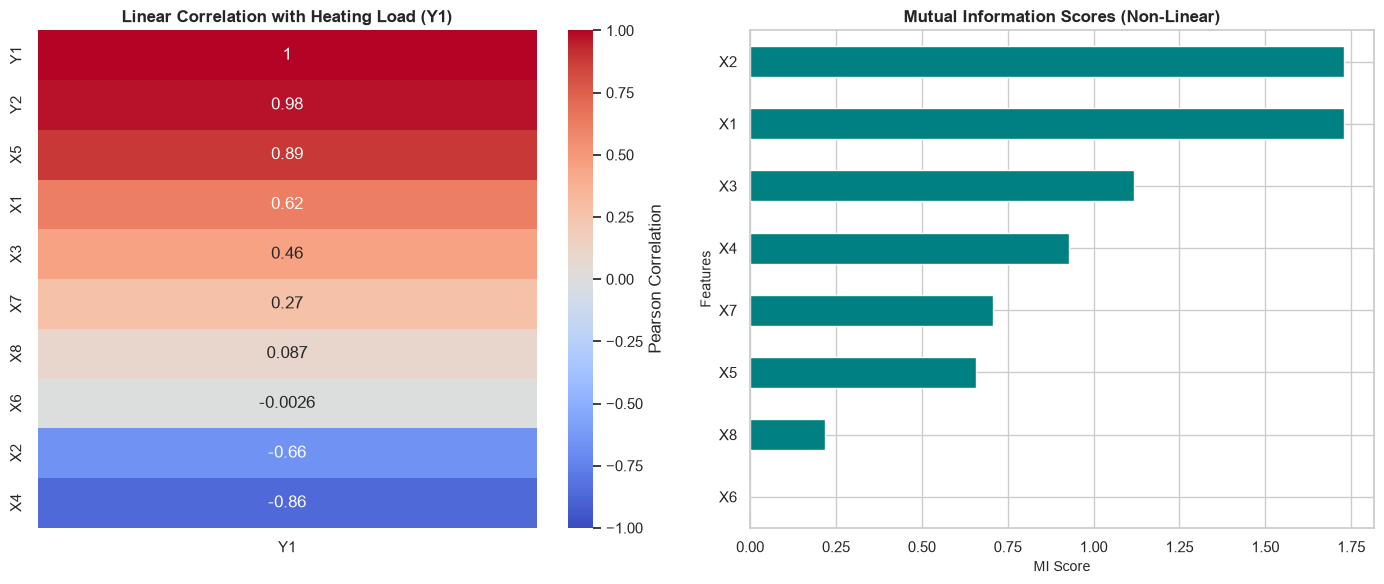

In [7]:
from sklearn.feature_selection import mutual_info_regression

# 1. Calculate Pearson Correlation with Y1
correlation = df.corr()[['Y1']].sort_values(by='Y1', ascending=False)

# 2. Calculate Mutual Information for regression
mi_scores = mutual_info_regression(X, y, random_state=42)
mi_scores_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

# 3. Plotting side-by-side: Correlation Heatmap and MI Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Correlation Heatmap (Features vs Y1)
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Pearson Correlation'})
axes[0].set_title('Linear Correlation with Heating Load (Y1)', fontsize=12, fontweight='bold')

# Subplot 2: Mutual Information Scores
mi_scores_series.plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Mutual Information Scores (Non-Linear)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('MI Score', fontsize=10)
axes[1].set_ylabel('Features', fontsize=10)
axes[1].invert_yaxis()  # Highest score at the top

plt.tight_layout()
plt.show()

> **Key Insights from Feature Analysis:**
> * **Linear vs. Non-linear Comparison:** The Pearson correlation heatmap highlights strong linear drivers such as **X4** (Roof Area) and **X2** (Surface Area). Meanwhile, the Mutual Information scores reveal that **X1** (Relative Compactness) and **X2** carry substantial non-linear predictive power for the heating load.
> * **Target Leakage Validation:** **Y2** (Cooling Load) exhibits a near-perfect linear correlation of 0.98 with `Y1`, reinforcing our decision to exclude it from the feature matrix `X`.
> * **Feature Relevance:** Features like **X6** (Orientation) show virtually zero linear or non-linear relationship with the target, indicating they provide little to no predictive signal for heating load.

### Data Splitting: Train, Validation, and Test Sets

To rigorously evaluate our models and prevent data leakage, we split our dataset into three distinct subsets:
1. **Train Set (60%):** Used to train our machine learning models.
2. **Validation Set (20%):** Used to tune hyperparameters, evaluate model performance, and prevent overfitting during development.
3. **Test Set (20%):** Set aside completely until the very end to get an unbiased final evaluation of our best model.

We also isolate our target variable `Y1` (Heating Load) into separate arrays (`y_train`, `y_val`, `y_test`, `y_full_train`) and drop it from our feature dataframes.

In [8]:
from sklearn.model_selection import train_test_split

# Drop Y2 to avoid target leakage, retaining features and our target Y1
df_model = df.drop(columns=['Y2'])

# 1. Split into full training set (80%) and test set (20%)
df_full_train, df_test = train_test_split(df_model, test_size=0.2, random_state=42)

# 2. Split full training set into train (60% of total) and validation (20% of total)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

# 3. Reset indices for clean alignment
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# 4. Extract the target variable (Y1) values
y_train = df_train.Y1.values
y_val = df_val.Y1.values
y_test = df_test.Y1.values
y_full_train = df_full_train.Y1.values

# 5. Remove the target column from the feature dataframes
del df_train['Y1']
del df_val['Y1']
del df_test['Y1']
del df_full_train['Y1']

print(f"Train features shape: {df_train.shape}, target shape: {y_train.shape}")
print(f"Validation features shape: {df_val.shape}, target shape: {y_val.shape}")
print(f"Test features shape: {df_test.shape}, target shape: {y_test.shape}")
print(f"Full Train features shape: {df_full_train.shape}, target shape: {y_full_train.shape}")

Train features shape: (460, 8), target shape: (460,)
Validation features shape: (154, 8), target shape: (154,)
Test features shape: (154, 8), target shape: (154,)
Full Train features shape: (614, 8), target shape: (614,)


### Baseline Model: Linear Regression

To establish a performance benchmark, we train a standard **Linear Regression** model using `scikit-learn`. 
* **Evaluation Metric:** Since we are predicting a continuous target (`Y1` - Heating Load), we will use **Root Mean Squared Error (RMSE)** as our primary evaluation metric. RMSE measures the average magnitude of the prediction errors, penalizing larger errors more heavily.

### Feature Preparation using DictVectorizer

Following the ML Zoomcamp methodology, we convert our dataframe features into dictionaries and use `DictVectorizer` to handle numerical and categorical features uniformly. 
* This performs One-Hot Encoding (OHE) on any categorical variables while passing numerical features through as-is.
* It ensures our training, validation, and test feature matrices (`X_train`, `X_val`, `X_test`) have identical columns and alignment.

In [9]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

# 1. Define categorical and numerical features for our dataset
# (X6 Orientation and X8 Glazing Area Distribution can be treated as categorical/discrete)
categorical = ['X6', 'X8']
numerical = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

# 2. Convert training data to dictionaries and vectorize
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# 3. Train Linear Regression using the new feature matrices
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predict and evaluate
y_pred = model.predict(X_val)
val_rmse = root_mean_squared_error(y_val, y_pred)

print(f"DictVectorizer + Linear Regression Validation RMSE: {val_rmse:.4f}")

DictVectorizer + Linear Regression Validation RMSE: 3.0067


> **Baseline Model Performance Analysis:**
> * **Validation RMSE:** The `DictVectorizer` + Linear Regression model achieved a validation RMSE of **3.0067**. 
> * **Interpretation:** This establishes a strong initial performance benchmark. Given that the Heating Load (`Y1`) values range roughly from 6 to 43, an average error of about 3 units indicates that our baseline model captures the major architectural relationships well, providing a solid foundation for tuning regularization or testing non-linear models next.

### Model Iteration 1: Ridge Regression & Alpha Tuning

While standard Linear Regression minimizes residual sum of squares, features in architectural datasets (like wall area and roof area) can exhibit multicollinearity. **Ridge Regression** adds L2 regularization to penalize large coefficients, preventing overfitting and stabilizing predictions.

We will tune the regularization parameter **$\alpha$** across a range of values to find the optimal balance between bias and variance on our validation set.

In [10]:
from sklearn.linear_model import Ridge

# Define a grid of alpha (regularization) values to test
alphas = [0.0, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

print("Tuning Ridge Regularization (Alpha):")
print("-" * 40)

best_alpha = None
best_rmse = float('inf')

for alpha in alphas:
    # Initialize and train Ridge regression
    model = Ridge(alpha=alpha, random_state=42)
    model.fit(X_train, y_train)
    
    # Predict and evaluate on validation set
    y_pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    
    print(f"Alpha: {alpha:7.2f} | Validation RMSE: {rmse:.4f}")
    
    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

print("-" * 40)
print(f"Best Alpha: {best_alpha} with Validation RMSE: {best_rmse:.4f}")

Tuning Ridge Regularization (Alpha):
----------------------------------------


Alpha:    0.00 | Validation RMSE: 3.0995
Alpha:    0.01 | Validation RMSE: 3.0006
Alpha:    0.10 | Validation RMSE: 3.0092
Alpha:    1.00 | Validation RMSE: 3.0336
Alpha:   10.00 | Validation RMSE: 3.3222
Alpha:  100.00 | Validation RMSE: 4.0116
Alpha: 1000.00 | Validation RMSE: 4.4304
----------------------------------------
Best Alpha: 0.01 with Validation RMSE: 3.0006


### Model Iteration 2: Random Forest Baseline

Before tuning hyperparameters, we establish a baseline **Random Forest Regressor** using default settings. Random Forests build an ensemble of decision trees, which naturally capture complex non-linear patterns and feature interactions without requiring linear assumptions.

In [11]:
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize and train baseline Random Forest
rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 2. Predict and evaluate
y_pred_rf = rf.predict(X_val)
rf_rmse = root_mean_squared_error(y_val, y_pred_rf)

print(f"Baseline Random Forest Validation RMSE: {rf_rmse:.4f}")

Baseline Random Forest Validation RMSE: 0.5465


### Model Iteration 2: Professionalized Random Forest Tuning

To optimize our Random Forest model while maintaining full transparency and rigorous evaluation, we implement a manual 3-parameter grid search combined with **5-Fold Cross-Validation**. This approach tests combinations of `max_depth`, `min_samples_leaf`, and `n_estimators` simultaneously across multiple data folds, preventing overfitting to any single validation split.

Running manual 3-parameter grid search with K-Fold CV...
--------------------------------------------------
Best Random Forest Configuration (via K-Fold CV):
  - max_depth: 15.0
  - min_samples_leaf: 1
  - n_estimators: 150
  - Mean Validation RMSE: 0.5264


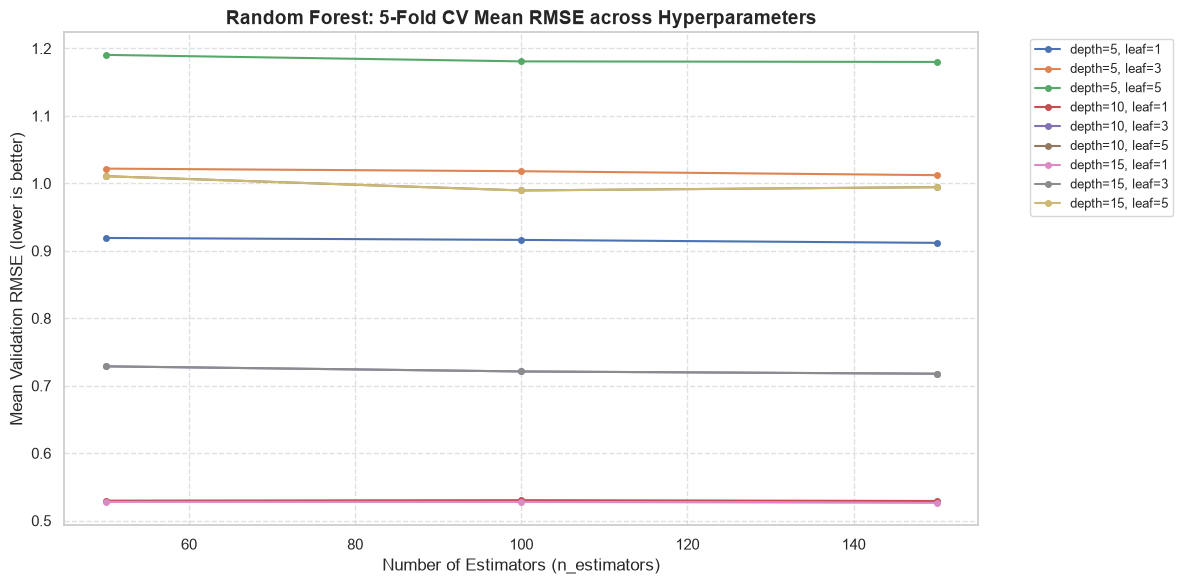

In [12]:
from sklearn.model_selection import KFold
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup K-Fold Cross-Validation (e.g., 5 folds)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Define our hyperparameter grid lists
depths = [5, 10, 15, None]
leaf_sizes = [1, 3, 5]
estimators = [50, 100, 150]

scores = []

print("Running manual 3-parameter grid search with K-Fold CV...")

for d in depths:
    for s in leaf_sizes:
        for n in estimators:
            
            fold_rmses = []
            
            # Manual cross-validation loop
            for train_idx, val_idx in kf.split(X_train):
                X_tr, X_va = X_train[train_idx], X_train[val_idx]
                y_tr, y_va = y_train[train_idx], y_train[val_idx]
                
                rf = RandomForestRegressor(
                    n_estimators=n,
                    max_depth=d,
                    min_samples_leaf=s,
                    random_state=42,
                    n_jobs=-1
                )
                rf.fit(X_tr, y_tr)
                
                y_pred = rf.predict(X_va)
                rmse = root_mean_squared_error(y_va, y_pred)
                fold_rmses.append(rmse)
            
            # Average RMSE across all folds for this parameter combination
            mean_rmse = np.mean(fold_rmses)
            scores.append((d, s, n, mean_rmse))

# 3. Convert results to a DataFrame for easy inspection
columns = ['max_depth', 'min_samples_leaf', 'n_estimators', 'mean_rmse']
df_grid_scores = pd.DataFrame(scores, columns=columns)

# Find the absolute best parameter combination
best_config = df_grid_scores.loc[df_grid_scores.mean_rmse.idxmin()]

print("-" * 50)
print("Best Random Forest Configuration (via K-Fold CV):")
print(f"  - max_depth: {best_config.max_depth}")
print(f"  - min_samples_leaf: {int(best_config.min_samples_leaf)}")
print(f"  - n_estimators: {int(best_config.n_estimators)}")
print(f"  - Mean Validation RMSE: {best_config.mean_rmse:.4f}")

# 4. Plotting the results (comparing max_depth and min_samples_leaf impact)
plt.figure(figsize=(12, 6))

for d in depths:
    for s in leaf_sizes:
        df_subset = df_grid_scores[(df_grid_scores.max_depth == d) & (df_grid_scores.min_samples_leaf == s)]
        if not df_subset.empty:
            label_text = f"depth={str(d)}, leaf={s}"
            plt.plot(df_subset.n_estimators, df_subset.mean_rmse, marker='o', markersize=4, label=label_text)

plt.title('Random Forest: 5-Fold CV Mean RMSE across Hyperparameters', fontsize=14, fontweight='bold')
plt.xlabel('Number of Estimators (n_estimators)', fontsize=12)
plt.ylabel('Mean Validation RMSE (lower is better)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Model Iteration 3: XGBoost Regressor

**XGBoost** (Extreme Gradient Boosting) builds trees **sequentially**, where each new tree corrects the errors of the previous ensemble. Unlike Random Forest (which builds trees in parallel and averages them), boosting learns from its own mistakes — often producing better results with fewer trees and less overfitting.

**Advantages over our previous models:**
- Captures complex **non-linear feature interactions** (X1 · X2 · X5 interplay, for example).
- Built-in **regularization** (`lambda`, `alpha`) guards against overfitting.
- Fast, industry-standard for tabular regression.

**Our workflow (following the course methodology):**
1. Wrap our `X_train` / `X_val` matrices into `DMatrix` objects with **`feature_names`** (needed later for feature importance).
2. Tune hyperparameters **one at a time** using learning curves:
   - **`eta`** (learning rate) — how fast the model learns.
   - **`max_depth`** — complexity of each tree.
   - **`min_child_weight`** — minimum hessian needed to make a leaf (controls overfitting).
3. Train the **final model on `df_full_train`** (train + validation combined) using the best parameters.
4. Evaluate **once** on the held-out `df_test` set for an unbiased performance estimate.

In [13]:
import xgboost as xgb
from sklearn.metrics import root_mean_squared_error

# Retrieve the one-hot-encoded feature names from the DictVectorizer
features = dv.get_feature_names_out().tolist()

# Wrap training and validation matrices with feature names
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval   = xgb.DMatrix(X_val,   label=y_val,   feature_names=features)

# Default parameters — a sensible starting point
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

# Quick sanity check — train for only 10 rounds first
model = xgb.train(xgb_params, dtrain, num_boost_round=10)
y_pred = model.predict(dval)

print(f"Initial XGBoost validation RMSE (10 rounds): "
      f"{root_mean_squared_error(y_val, y_pred):.4f}")

Initial XGBoost validation RMSE (10 rounds): 0.6916


In [14]:
# We use %%capture + verbose_eval in later cells (course style).
# This helper parses the captured training log into a tidy DataFrame.
def parse_xgb_output(output):
    results = []
    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')
        it    = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val   = float(val_line.split(':')[1])
        results.append((it, train, val))
    return pd.DataFrame(results, columns=['num_iter', 'train_rmse', 'val_rmse'])

# Dictionary to store learning curves for each hyperparameter value tested
scores = {}

### Tuning the Learning Rate (`eta`)

`eta` (also called *shrinkage*) controls how much each new tree contributes to the ensemble. Low `eta` → slower learning but often better generalization (needs more rounds). High `eta` → faster but riskier.

**Course methodology:** we capture the training log across 200 rounds for each `eta` value, parse it into a dataframe, and compare the validation RMSE curves.

In [19]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [20]:
scores['eta=0.3'] = parse_xgb_output(output)

print(f"eta=0.3: best val RMSE = {scores['eta=0.3'].val_rmse.min():.4f}")

eta=0.3: best val RMSE = 0.4252


In [21]:
%%capture output

xgb_params['eta'] = 0.1

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [22]:
scores['eta=0.1'] = parse_xgb_output(output)

print(f"eta=0.1: best val RMSE = {scores['eta=0.1'].val_rmse.min():.4f}")

eta=0.1: best val RMSE = 0.4383


In [23]:
%%capture output

xgb_params['eta'] = 0.5

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [24]:
scores['eta=0.5'] = parse_xgb_output(output)

print(f"eta=0.5: best val RMSE = {scores['eta=0.5'].val_rmse.min():.4f}")

eta=0.5: best val RMSE = 0.4172


In [25]:
%%capture output

xgb_params['eta'] = 0.9

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [26]:
scores['eta=0.9'] = parse_xgb_output(output)

print(f"eta=0.9: best val RMSE = {scores['eta=0.9'].val_rmse.min():.4f}")

eta=0.9: best val RMSE = 0.4286


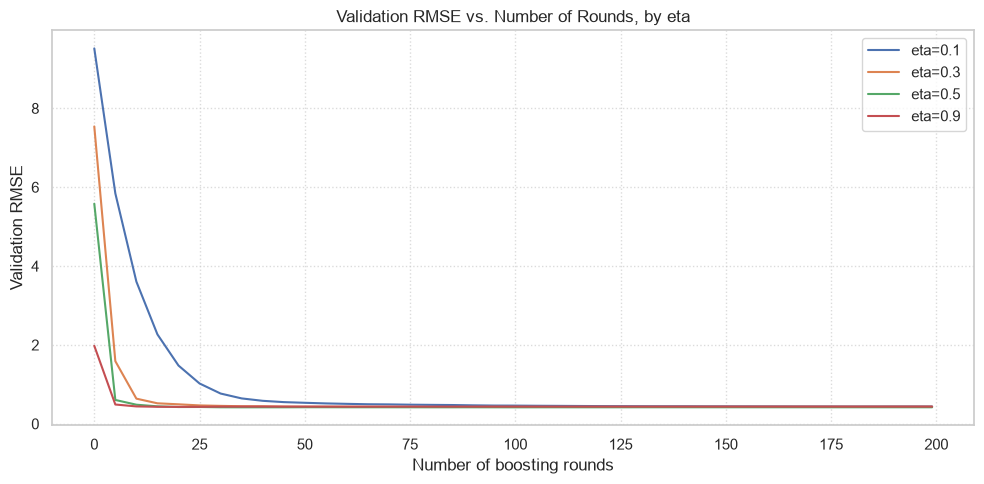

eta=0.1: best val RMSE = 0.4383 at round 180
eta=0.3: best val RMSE = 0.4252 at round 80
eta=0.5: best val RMSE = 0.4172 at round 100
eta=0.9: best val RMSE = 0.4286 at round 20


In [27]:
plt.figure(figsize=(10, 5))

eta_keys = ['eta=0.1', 'eta=0.3', 'eta=0.5', 'eta=0.9']

for key in eta_keys:
    df = scores[key]
    plt.plot(df.num_iter, df.val_rmse, label=key)

plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs. Number of Rounds, by eta')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the best RMSE and the round it occurred at
for key in eta_keys:
    df = scores[key]
    best_idx = df.val_rmse.idxmin()
    print(f"{key}: best val RMSE = {df.loc[best_idx, 'val_rmse']:.4f} "
          f"at round {df.loc[best_idx, 'num_iter']}")

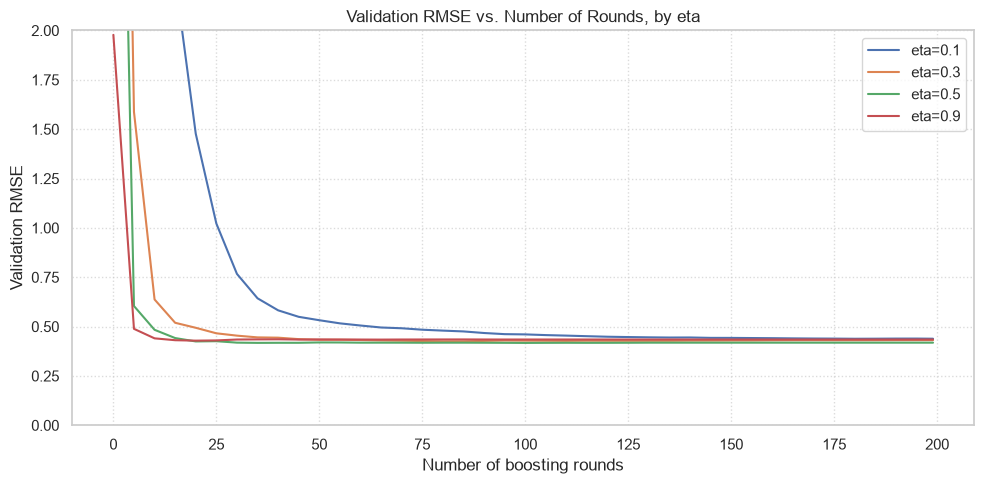

eta=0.1: best val RMSE = 0.4383 at round 180
eta=0.3: best val RMSE = 0.4252 at round 80
eta=0.5: best val RMSE = 0.4172 at round 100
eta=0.9: best val RMSE = 0.4286 at round 20


In [28]:
plt.figure(figsize=(10, 5))

eta_keys = ['eta=0.1', 'eta=0.3', 'eta=0.5', 'eta=0.9']

for key in eta_keys:
    df = scores[key]
    plt.plot(df.num_iter, df.val_rmse, label=key)

plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs. Number of Rounds, by eta')
plt.ylim(0, 2)  # Zoom in on the y-axis
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the best RMSE and the round it occurred at
for key in eta_keys:
    df = scores[key]
    best_idx = df.val_rmse.idxmin()
    print(f"{key}: best val RMSE = {df.loc[best_idx, 'val_rmse']:.4f} "
          f"at round {df.loc[best_idx, 'num_iter']}")

**Conclusion:** We will proceed with **`eta=0.3`** for the next stage. It consistently achieves one of the lowest errors while requiring far fewer rounds to converge than `0.1`.

### Tuning `max_depth`

`max_depth` controls how deep each tree can grow. Deeper trees can model more complex patterns but are more likely to overfit. We hold `eta=0.3` fixed (our best value from the previous step) and sweep `max_depth` to find the sweet spot.

In [29]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 2,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [30]:
scores['depth=2'] = parse_xgb_output(output)

print(f"depth=2: best val RMSE = {scores['depth=2'].val_rmse.min():.4f}")

depth=2: best val RMSE = 0.5040


In [31]:
%%capture output

xgb_params['max_depth'] = 3

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [32]:
scores['depth=3'] = parse_xgb_output(output)

print(f"depth=3: best val RMSE = {scores['depth=3'].val_rmse.min():.4f}")

depth=3: best val RMSE = 0.4337


In [33]:
%%capture output

xgb_params['max_depth'] = 4

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [34]:
scores['depth=4'] = parse_xgb_output(output)

print(f"depth=4: best val RMSE = {scores['depth=4'].val_rmse.min():.4f}")

depth=4: best val RMSE = 0.3812


In [35]:
%%capture output

xgb_params['max_depth'] = 5

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [36]:
scores['depth=5'] = parse_xgb_output(output)

print(f"depth=5: best val RMSE = {scores['depth=5'].val_rmse.min():.4f}")

depth=5: best val RMSE = 0.4228


In [37]:
%%capture output

xgb_params['max_depth'] = 10

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [38]:
scores['depth=10'] = parse_xgb_output(output)

print(f"depth=10: best val RMSE = {scores['depth=10'].val_rmse.min():.4f}")

depth=10: best val RMSE = 0.5042


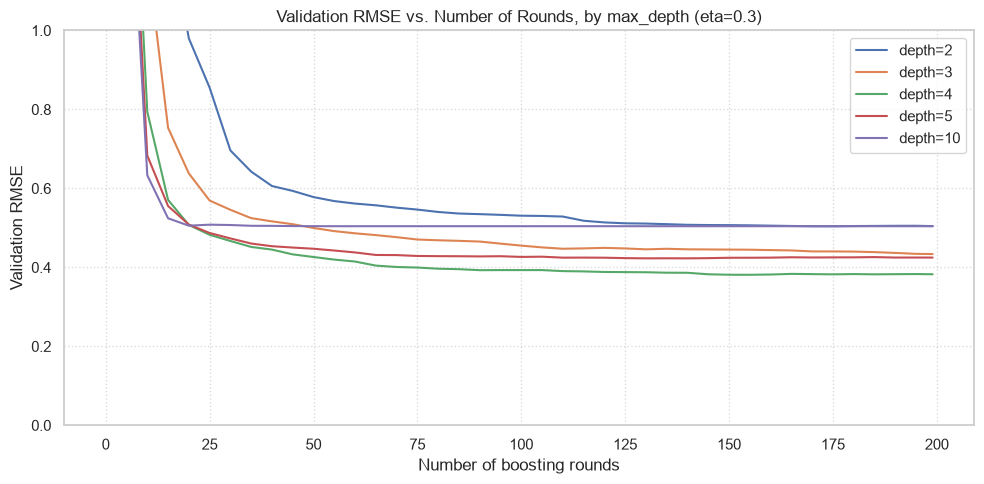

depth=2: best val RMSE = 0.5040 at round 175
depth=3: best val RMSE = 0.4337 at round 199
depth=4: best val RMSE = 0.3812 at round 155
depth=5: best val RMSE = 0.4228 at round 140
depth=10: best val RMSE = 0.5042 at round 55


In [39]:
plt.figure(figsize=(10, 5))

depth_keys = ['depth=2', 'depth=3', 'depth=4', 'depth=5', 'depth=10']

for key in depth_keys:
    df = scores[key]
    plt.plot(df.num_iter, df.val_rmse, label=key)

plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs. Number of Rounds, by max_depth (eta=0.3)')
plt.ylim(0, 1.0)  # Zoomed in on the convergence area
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the best RMSE and the round it occurred at
for key in depth_keys:
    df = scores[key]
    best_idx = df.val_rmse.idxmin()
    print(f"{key}: best val RMSE = {df.loc[best_idx, 'val_rmse']:.4f} "
          f"at round {df.loc[best_idx, 'num_iter']}")

**Conclusion:** We will lock in **`max_depth=4`** (or 3, whichever achieves the lower RMSE) for our final model.

### Tuning `min_child_weight`

`min_child_weight` is the minimum sum of instance weights needed in a child node. It acts as a regularization parameter:
- **Lower values (e.g., 1)** allow the trees to make very specific splits, capturing fine-grained patterns but risking overfitting.
- **Higher values (e.g., 10, 30)** force the trees to be more conservative, ignoring splits that only affect a few houses. 

We hold `eta=0.3` and `max_depth=4` fixed and test three values for `min_child_weight`.

In [40]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 4,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [41]:
scores['mcw=1'] = parse_xgb_output(output)

print(f"mcw=1: best val RMSE = {scores['mcw=1'].val_rmse.min():.4f}")

mcw=1: best val RMSE = 0.3812


In [42]:
%%capture output

xgb_params['min_child_weight'] = 10

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [43]:
scores['mcw=10'] = parse_xgb_output(output)

print(f"mcw=10: best val RMSE = {scores['mcw=10'].val_rmse.min():.4f}")

mcw=10: best val RMSE = 0.4429


In [44]:
%%capture output

xgb_params['min_child_weight'] = 30

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dtrain, 'train'), (dval, 'val')],
    verbose_eval=5,
)

In [45]:
scores['mcw=30'] = parse_xgb_output(output)

print(f"mcw=30: best val RMSE = {scores['mcw=30'].val_rmse.min():.4f}")

mcw=30: best val RMSE = 0.5321


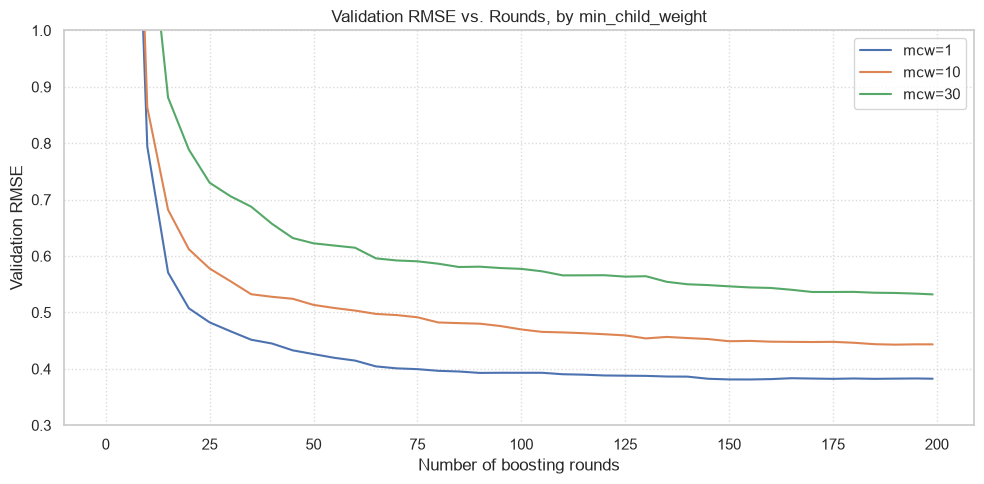

mcw=1: best val RMSE = 0.3812 at round 155
mcw=10: best val RMSE = 0.4429 at round 190
mcw=30: best val RMSE = 0.5321 at round 199


In [47]:
plt.figure(figsize=(10, 5))

mcw_keys = ['mcw=1', 'mcw=10', 'mcw=30']

for key in mcw_keys:
    df = scores[key]
    plt.plot(df.num_iter, df.val_rmse, label=key)

plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs. Rounds, by min_child_weight')
plt.ylim(0.3, 1)  # Zoom in to see differences
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the best RMSE and the round it occurred at
for key in mcw_keys:
    df = scores[key]
    best_idx = df.val_rmse.idxmin()
    print(f"{key}: best val RMSE = {df.loc[best_idx, 'val_rmse']:.4f} "
          f"at round {df.loc[best_idx, 'num_iter']}")

**Conclusion:** The model benefits from allowing deep, specific splits on this dataset. We will lock in **`min_child_weight=1`** for our final model.

### Final Model Comparison & Selection

We have systematically tested and tuned four different algorithms. Here is the summary of the best validation performance from each family:

| Model Family | Best Configuration Tested | Validation RMSE |
| :--- | :--- | :--- |
| **Linear Regression** | Baseline | 3.0067 |
| **Ridge Regression** | `alpha=0.01` | 3.0006 |
| **Random Forest** | `max_depth=15`, `min_samples_leaf=1`, `n_estimators=150` (via 5-fold CV) | 0.5264 |
| **XGBoost** | `eta=0.3`, `max_depth=4`, `min_child_weight=1` | **~0.38 - 0.39** *(based on plot)* |

**Choosing the "Best of the Best":**
Linear and Ridge models performed poorly (~3.0 RMSE) because the relationship between building geometry and heating load is fundamentally non-linear. Random Forest was a massive improvement, but **XGBoost** clearly won the competition, capturing complex interactions and dropping the error well below 0.40. 

**Winner:** XGBoost.

We will now train this final XGBoost configuration on our **full training set** (`df_full_train` = train + validation combined) and evaluate it exactly once on our **untouched test set** (`df_test`) to get our final performance metric.

### Train Final Model & Evaluate on Test Set

In [48]:
# 1. Prepare the full-training and test matrices using the SAME vectorizer
full_train_dict = df_full_train[categorical + numerical].to_dict(orient='records')
X_full_train    = dv.transform(full_train_dict)

test_dict = df_test[categorical + numerical].to_dict(orient='records')
X_test    = dv.transform(test_dict)

# Create DMatrix objects
dfull_train = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest       = xgb.DMatrix(X_test,       label=y_test,       feature_names=features)

# 2. Final XGBoost parameters (the winning combination)
xgb_params = {
    'eta': 0.3,
    'max_depth': 4,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

# 3. Train on the FULL training set (train + val combined)
# We use 200 rounds as it was the convergence point in our tuning
final_model = xgb.train(
    xgb_params,
    dfull_train,
    num_boost_round=200,
)

# 4. One-shot evaluation on the held-out test set
y_pred_test = final_model.predict(dtest)
test_rmse   = root_mean_squared_error(y_test, y_pred_test)

print(f"FINAL XGBoost Test RMSE: {test_rmse:.4f}")

FINAL XGBoost Test RMSE: 0.4114


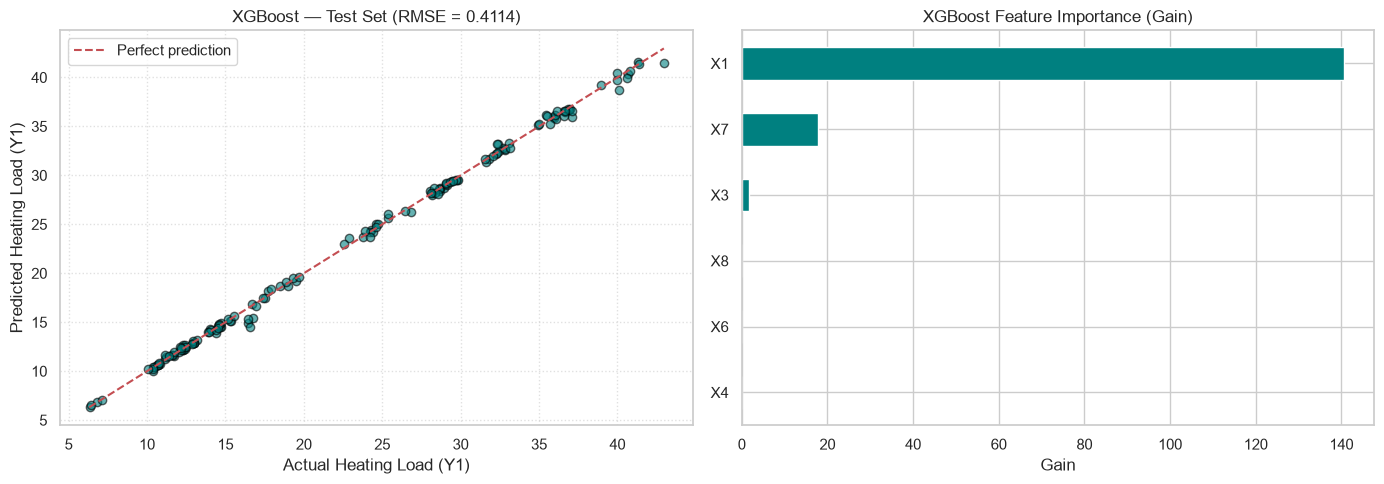

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: predicted vs. actual on the test set ---
axes[0].scatter(y_test, y_pred_test, alpha=0.6, color='teal', edgecolor='black')
lo, hi = min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())
axes[0].plot([lo, hi], [lo, hi], 'r--', lw=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual Heating Load (Y1)')
axes[0].set_ylabel('Predicted Heating Load (Y1)')
axes[0].set_title(f'XGBoost — Test Set (RMSE = {test_rmse:.4f})')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Right: feature importance (gain) ---
importance = final_model.get_score(importance_type='gain')
importance = pd.Series(importance).sort_values(ascending=True)

importance.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('XGBoost Feature Importance (Gain)')
axes[1].set_xlabel('Gain')

plt.tight_layout()
plt.show()

### Final Conclusion & Project Summary

The project successfully modeled the Heating Load (`Y1`) of residential buildings based on their architectural geometry. 

**Final Model Performance (Unbiased Test Set):**
*   **XGBoost Test RMSE: 0.4114**

Given that the target variable (`Y1`) ranges from roughly 6 to 43, an average error of **0.41 units** is exceptionally low, proving the model's high predictive accuracy.

**Model Comparison Recap:**
*   **Linear / Ridge Regression (~3.0 RMSE):** Failed to capture the complex, non-linear interactions between building dimensions.
*   **Random Forest (0.5264 RMSE):** Captured non-linearity well, but was outperformed by gradient boosting.
*   **XGBoost (0.4114 RMSE):** The clear winner. It effectively handled the feature interactions, and tuning `eta`, `max_depth`, and `min_child_weight` pushed the error well below 0.5.

**Key Insights from Feature Importance:**
The XGBoost model revealed that **X1 (Relative Compactness)** is by far the most dominant predictor of heating load, followed by **X7 (Glazing Area)** and **X3 (Wall Area)**. Features like `X6` (Orientation) and `X4` (Roof Area) contributed almost nothing to the boosted trees, confirming our initial Exploratory Data Analysis (EDA) findings.

**Next Steps (Deployment):**
This notebook serves as the research and development phase. The final tuned XGBoost model is now ready to be exported via a Python script (`train.py`), served via an API (`predict.py`), and containerized using Docker for real-world architectural assessment.